# Cubed-sphere SECS and MNOC workflow

Load the SuperMAG data, fit the cubed-sphere SECS model, predict `psi` on the evaluation grid, run MNOC decomposition, show the four-panel summary, and save equivalent-current vector diagrams.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from mnoc import mnoc, psi_to_current
from set_up_secs import SECSFit

NOTEBOOK_DIR = Path.cwd()
DATA_PATH = (
    NOTEBOOK_DIR.parent
    / 'data'
    / 'all_stations'
    / 'SuperMAG_60s_20231201_rev-0006.1783148935.netcdf'
)
N_MODES = 2

np.set_printoptions(precision=4, suppress=True, linewidth=160)
print('data path:', DATA_PATH)
print('retained MNOC modes:', N_MODES)

data path: /home/jijin/equivalent_current/supermag+secs+mnoc/data/all_stations/SuperMAG_60s_20231201_rev-0006.1783148935.netcdf
retained MNOC modes: 2


## 1. Load data, fit model, and predict on the evaluation grid

In [2]:
fit = SECSFit(DATA_PATH).fit()
psi = fit.predict_psi()

print('times:', fit.times.shape)
print('stations:', fit.obs_loc.shape[0])
print('pole points:', fit.pole_loc.shape[0])
print('evaluation points:', fit.eval_loc.shape[0])
print('sec_amps:', fit.sec_amps.shape)
print('psi:', psi.shape)
print('finite psi:', np.isfinite(psi).sum(), '/', psi.size)

times: (1440,)
stations: 105
pole points: 624
evaluation points: 440
sec_amps: (1440, 624)
psi: (1440, 440)
finite psi: 633600 / 633600


## 2. MNOC decomposition of psi

In [3]:
T, X, eigvals, psi_modes, power_fraction = mnoc(
    psi,
    n_modes=N_MODES,
    cell_area_m2=fit.eval_grid.eval_cell_area,
)

total_current = psi_to_current(psi)
mode1_current = psi_to_current(psi_modes[0])
mode2_current = psi_to_current(psi_modes[1])
residual_current = total_current - mode1_current - mode2_current
contribution = 100.0 * power_fraction
times = pd.to_datetime(fit.times, utc=True)

print('T:', T.shape)
print('X:', X.shape)
print('eigvals:', eigvals.shape)
print('psi_modes:', psi_modes.shape)
print('total current range [kA]:', total_current.min(), total_current.max())
print('mode 1 current range [kA]:', mode1_current.min(), mode1_current.max())
print('mode 2 current range [kA]:', mode2_current.min(), mode2_current.max())
print('residual current range [kA]:', residual_current.min(), residual_current.max())
print('mode 1 contribution [%]:', contribution[0])

T: (1440, 2)
X: (2, 440)
eigvals: (2,)
psi_modes: (2, 1440, 440)
total current range [kA]: 67.24278316259775 2572.5418107976284
mode 1 current range [kA]: 0.01667396181134754 1189.0752576822442
mode 2 current range [kA]: 0.007274853491916253 979.5788732785231
residual current range [kA]: -535.9975247934304 1390.1367384319178
mode 1 contribution [%]: 89.02159594144221


## 3. Four-panel MNOC summary

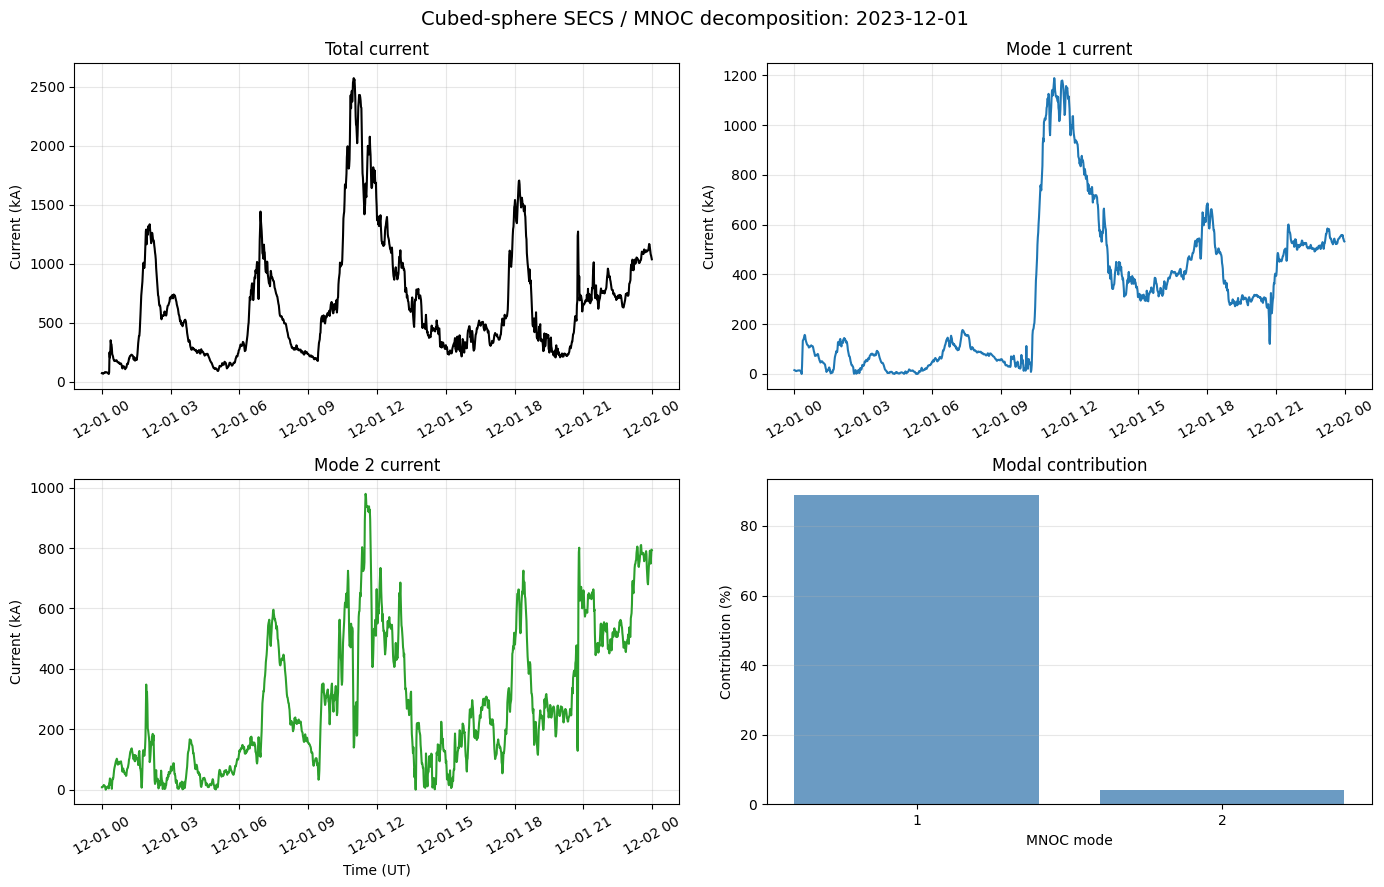

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
modes = np.arange(1, len(contribution) + 1)

axes[0, 0].plot(times, total_current, color='k', lw=1.5)
axes[0, 0].set_ylabel('Current (kA)')
axes[0, 0].set_title('Total current')
axes[0, 0].grid(alpha=0.3)

axes[0, 1].plot(times, mode1_current, color='tab:blue', lw=1.5)
axes[0, 1].set_ylabel('Current (kA)')
axes[0, 1].set_title('Mode 1 current')
axes[0, 1].grid(alpha=0.3)

axes[1, 0].plot(times, mode2_current, color='tab:green', lw=1.5)
axes[1, 0].set_xlabel('Time (UT)')
axes[1, 0].set_ylabel('Current (kA)')
axes[1, 0].set_title('Mode 2 current')
axes[1, 0].grid(alpha=0.3)

axes[1, 1].bar(modes, contribution, color='steelblue', alpha=0.8)
axes[1, 1].set_xlabel('MNOC mode')
axes[1, 1].set_ylabel('Contribution (%)')
axes[1, 1].set_title('Modal contribution')
axes[1, 1].set_xticks(modes)
axes[1, 1].grid(axis='y', alpha=0.3)

for axis in axes.flat[:3]:
    axis.tick_params(axis='x', rotation=30)

fig.suptitle('Cubed-sphere SECS / MNOC decomposition: 2023-12-01', fontsize=14)
fig.tight_layout()
plt.show()

## 4. Equivalent-current vector diagrams from 10 UT to 20 UT

Save one vector diagram per available frame in the interval into `../figures/vector_diagrams`.


In [5]:
# from eq_current_vector_map import plot_eq_current_vector_map

# VECTOR_START_HOUR_UT = 10
# VECTOR_END_HOUR_UT = 20
# VECTOR_CADENCE_MINUTES = 1

# vector_times = pd.to_datetime(fit.times, utc=True)
# day_start = vector_times[0].normalize()
# vector_start_time = day_start + pd.Timedelta(hours=VECTOR_START_HOUR_UT)
# vector_end_time = day_start + pd.Timedelta(hours=VECTOR_END_HOUR_UT)
# vector_time_mask = (
#     (vector_times >= vector_start_time)
#     & (vector_times <= vector_end_time)
# )
# vector_frame_indices = np.flatnonzero(vector_time_mask)
# if VECTOR_CADENCE_MINUTES > 1:
#     vector_frame_indices = vector_frame_indices[::VECTOR_CADENCE_MINUTES]

# vector_diagram_dir = NOTEBOOK_DIR.parent / 'figures' / 'vector_diagrams'
# vector_diagram_dir.mkdir(parents=True, exist_ok=True)

# print('vector interval:', vector_start_time, 'to', vector_end_time)
# print('frames to save:', vector_frame_indices.size)
# print('output directory:', vector_diagram_dir)

# for saved_count, frame_index in enumerate(vector_frame_indices, start=1):
#     frame_time = vector_times[frame_index]
#     output_path = vector_diagram_dir / (
#         f'eq_current_{frame_time:%Y%m%d_%H%M}UT.png'
#     )
#     plot_eq_current_vector_map(
#         fit.eval_loc,
#         fit.J[frame_index],
#         frame_time.to_pydatetime(),
#         reference_magnitude=2.0,
#         reference_length_degrees=5.0,
#         save_path=output_path,
#     )
#     if saved_count % 60 == 0 or saved_count == vector_frame_indices.size:
#         print(f'saved {saved_count}/{vector_frame_indices.size}: {output_path.name}')

# print('saved vector diagrams:', vector_frame_indices.size)


In [6]:
# # Assemble the saved vector-diagram frames in timestamp order.
# import subprocess

# VIDEO_FPS = 6
# video_path = vector_diagram_dir / 'eq_current_vectors.mp4'
# concat_path = vector_diagram_dir / 'eq_current_vectors.ffconcat'

# # The YYYYMMDD_HHMM portion of each filename is the frame time index.
# video_frames = sorted(
#     vector_diagram_dir.glob('eq_current_*UT.png'),
#     key=lambda path: pd.to_datetime(
#         path.stem.removeprefix('eq_current_').removesuffix('UT'),
#         format='%Y%m%d_%H%M',
#         utc=True,
#     ),
# )
# if not video_frames:
#     raise FileNotFoundError(f'No vector-diagram PNGs found in {vector_diagram_dir}')

# frame_duration = 1 / VIDEO_FPS
# concat_lines = ['ffconcat version 1.0']
# for frame_path in video_frames:
#     concat_lines.extend((f"file '{frame_path.resolve()}'", f'duration {frame_duration}'))
# # Repeat the final frame so its duration is retained by the concat demuxer.
# concat_lines.append(f"file '{video_frames[-1].resolve()}'")
# concat_path.write_text('\n'.join(concat_lines) + '\n')

# try:
#     subprocess.run(
#         [
#             'ffmpeg', '-y', '-f', 'concat', '-safe', '0', '-i', str(concat_path),
#             '-vsync', 'vfr', '-vf', 'pad=ceil(iw/2)*2:ceil(ih/2)*2',
#             '-c:v', 'libx264', '-crf', '18', '-pix_fmt', 'yuv420p',
#             '-movflags', '+faststart',
#             str(video_path),
#         ],
#         check=True,
#     )
# finally:
#     concat_path.unlink(missing_ok=True)

# print(f'created video from {len(video_frames)} time-sorted frames: {video_path}')
